# Cross-Domain Transfer - Source-Domain Models Applied to Sri Lanka

This notebook implements the **source-to-target (ST) transfer step** referenced in Chapter 4 /
Chapter 5 (5.3.3, 5.6.3) but not yet present in the `08a/08b/08c` modelling notebooks, which
each train and evaluate a model **only within its own country**.

## What this notebook does

1. Loads the Sri Lanka held-out test split already created by `08c_Sri_Lanka_modeling.ipynb`
   (`sri_lanka_X_test_raw.csv`, `sri_lanka_y_test.csv`) — so the transfer results are evaluated
   on **exactly the same rows** as the Sri Lanka baseline (B), making the B vs. ST comparison fair.
2. For each source domain (Indonesia, Kerala, Thailand), builds a **transfer-restricted feature
   set** — only the conditioning factors that are genuinely comparable across countries — and
   trains a fresh model on the source domain using *only* those features.
3. Applies each transfer model directly to the Sri Lanka test set (no fine-tuning; pure zero-shot
   transfer) and reports the same metric suite used for the baseline.
   

## Why a restricted, re-trained feature set (not the saved 08a/08b/08c models directly)

The models already saved by `08a/08b/08c` were trained on each country's **full** local factor
set, which is not identical across countries:

- Indonesia's categorical factor is `landuse` (a locally supplied raster classification) and it
  has **no SoilGrids variables** at all — it cannot be aligned with Kerala/Thailand/Sri Lanka's
  soil or landcover columns.
- `geologi` codes are assigned **independently per country** (see `07i`'s own note), so the same
  integer does not mean the same lithology across domains — it is excluded from every transfer
  variant here.
- Kerala and Thailand's `landcover` *is* the same ESA WorldCover 2021 scheme Sri Lanka uses, so
  it is safe to keep for those two sources only.

Feeding Sri Lanka data through a model trained on a feature space it doesn't share (e.g. asking
Sri Lanka's `landcover` to stand in for Indonesia's `landuse`) would silently corrupt the
comparison. Retraining a source model restricted to the columns that are *actually* shared is the
defensible way to do this transfer, and it costs very little extra code since the training
pipeline is identical to `08a/08b/08c`.

**Two transfer tiers:**

| Tier | Features | Applies to |
|---|---|---|
| `terrain_core` | elev, slope, aspect, planc, profc, twi, spi (7) | Indonesia, Kerala, Thailand |
| `terrain_soil_landcover` | terrain(7) + clay, sand, soc, bdod + landcover | Kerala, Thailand only |


## 0. Setup

In [9]:
from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, brier_score_loss,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path.cwd().resolve().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROCESSED_DIR / "models"
FIGURE_DIR = PROCESSED_DIR / "figures" / "cross_domain_transfer"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Processed dir:", PROCESSED_DIR)

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
    print("XGBoost:", xgb.__version__)
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not installed -- only Random Forest transfer models will run.")


Processed dir: D:\PROJECTS\Landslide_prediction\data\processed
XGBoost: 3.0.0


## 1. Load the Sri Lanka target-domain test set

Reusing the split already produced by `08c_Sri_Lanka_modeling.ipynb` keeps the transfer
evaluation on the identical rows used for the Sri Lanka baseline (B), so the comparison in
Chapter 5 is apples-to-apples rather than a different random split.

In [10]:
sl_X_test_raw = pd.read_csv(PROCESSED_DIR / "sri_lanka_X_test_raw.csv")
sl_y_test = pd.read_csv(PROCESSED_DIR / "sri_lanka_y_test.csv").squeeze("columns")

print("Sri Lanka target-domain test set:", sl_X_test_raw.shape)
print("Columns available:", sl_X_test_raw.columns.tolist())
print("Class balance:\n", sl_y_test.value_counts())


Sri Lanka target-domain test set: (293, 20)
Columns available: ['elev', 'slope', 'aspect', 'planc', 'profc', 'twi', 'spi', 'clay', 'sand', 'soc', 'bdod', 'dist_to_river', 'dist_to_road', 'rain_1d', 'rain_3d', 'rain_7d', 'rain_15d', 'rain_30d', 'landcover', 'geologi']
Class balance:
 label
0    147
1    146
Name: count, dtype: int64


## 2. Evaluation helper (same metric suite as the baseline notebooks)

In [11]:
def evaluate_binary_classifier(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    return {
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y, y_pred),
        "tss": sensitivity + specificity - 1,
        "roc_auc": roc_auc_score(y, y_proba),
        "pr_auc": average_precision_score(y, y_proba),
        "brier": brier_score_loss(y, y_proba),
        "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }


## 3. Define the transfer feature tiers

`TERRAIN_CORE` is the only tier valid for Indonesia (no soil data, and its `landuse` layer is not
the same scheme as Sri Lanka's `landcover`). `TERRAIN_SOIL_LANDCOVER` is used for Kerala and
Thailand, which share SoilGrids and ESA WorldCover with Sri Lanka.

In [12]:
TERRAIN_CORE = ["elev", "slope", "aspect", "planc", "profc", "twi", "spi"]
SOIL = ["clay", "sand", "soc", "bdod"]
LANDCOVER = ["landcover"]

SOURCE_CONFIG = {
    "Indonesia": {
        "csv": PROCESSED_DIR / "training_table_indonesia_extended.csv",
        "tiers": {
            "terrain_core": {"continuous": TERRAIN_CORE, "categorical": []},
        },
    },
    "Kerala": {
        "csv": PROCESSED_DIR / "training_table_kerala_extended.csv",
        "tiers": {
            "terrain_core": {"continuous": TERRAIN_CORE, "categorical": []},
            "terrain_soil_landcover": {"continuous": TERRAIN_CORE + SOIL, "categorical": LANDCOVER},
        },
    },
    "Thailand": {
        "csv": PROCESSED_DIR / "training_table_thailand_extended.csv",
        "tiers": {
            "terrain_core": {"continuous": TERRAIN_CORE, "categorical": []},
            "terrain_soil_landcover": {"continuous": TERRAIN_CORE + SOIL, "categorical": LANDCOVER},
        },
    },
}

for name, cfg in SOURCE_CONFIG.items():
    print(name, "->", cfg["csv"].name, "| exists:", cfg["csv"].exists())


Indonesia -> training_table_indonesia_extended.csv | exists: True
Kerala -> training_table_kerala_extended.csv | exists: True
Thailand -> training_table_thailand_extended.csv | exists: True


## 4. Train each transfer model and score it on the Sri Lanka test set

Random Forest is used consistently across every source/tier so that differences in the results
reflect the **domain being transferred from**, not a different algorithm being compared. Swap in
your own tuned hyperparameters (e.g. from `rf_search.best_params_` in the corresponding `08*`
notebook) if you want the transfer models tuned per source as well.

In [13]:
def build_preprocessor(continuous_cols, categorical_cols):
    transformers = []
    if continuous_cols:
        transformers.append(("continuous", StandardScaler(), continuous_cols))
    if categorical_cols:
        transformers.append(("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols))
    return ColumnTransformer(transformers)


def make_estimator(algorithm_name):
    if algorithm_name == "Random Forest":
        return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
    if algorithm_name == "XGBoost":
        return xgb.XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    raise ValueError(f"Unknown algorithm: {algorithm_name}")


def train_transfer_model(source_df, continuous_cols, categorical_cols, algorithm_name):
    feature_cols = continuous_cols + categorical_cols
    df = source_df.dropna(subset=feature_cols + ["label"]).reset_index(drop=True)

    X = df[feature_cols]
    y = df["label"].astype(int)

    preprocessor = build_preprocessor(continuous_cols, categorical_cols)
    model = make_estimator(algorithm_name)
    pipeline = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipeline.fit(X, y)

    return pipeline, len(df)


ALGORITHMS = ["Random Forest", "XGBoost"] if XGBOOST_AVAILABLE else ["Random Forest"]

transfer_results = []
fitted_pipelines = {}

for source_name, cfg in SOURCE_CONFIG.items():
    if not cfg["csv"].exists():
        print(f"Skipping {source_name}: {cfg['csv']} not found.")
        continue

    source_df = pd.read_csv(cfg["csv"])

    for tier_name, cols in cfg["tiers"].items():
        continuous_cols = cols["continuous"]
        categorical_cols = cols["categorical"]
        feature_cols = continuous_cols + categorical_cols

        missing_in_sl = [c for c in feature_cols if c not in sl_X_test_raw.columns]
        if missing_in_sl:
            print(f"Skipping {source_name}/{tier_name}: Sri Lanka is missing {missing_in_sl}")
            continue

        sl_eval_df = sl_X_test_raw[feature_cols].copy()
        valid_mask = sl_eval_df.notna().all(axis=1)

        for algorithm_name in ALGORITHMS:
            pipeline, n_source_rows = train_transfer_model(
                source_df, continuous_cols, categorical_cols, algorithm_name
            )
            key = f"{source_name} ({tier_name}, {algorithm_name})"
            fitted_pipelines[key] = pipeline

            result = evaluate_binary_classifier(
                pipeline,
                sl_eval_df.loc[valid_mask],
                sl_y_test.loc[valid_mask],
            )
            result["scenario"] = f"ST-{source_name}"
            result["feature_tier"] = tier_name
            result["algorithm"] = algorithm_name
            result["n_features"] = len(feature_cols)
            result["n_source_train_rows"] = n_source_rows
            result["n_target_eval_rows"] = int(valid_mask.sum())
            transfer_results.append(result)

            print(f"Done: {key}  |  F1={result['f1']:.4f}  ROC-AUC={result['roc_auc']:.4f}")

transfer_results_df = pd.DataFrame(transfer_results)
display_cols = ["scenario", "feature_tier", "algorithm", "n_features", "n_target_eval_rows",
                 "accuracy", "precision", "recall", "f1", "roc_auc", "mcc", "tss"]
transfer_results_df[display_cols].round(4)

Done: Indonesia (terrain_core, Random Forest)  |  F1=0.5704  ROC-AUC=0.6228
Done: Indonesia (terrain_core, XGBoost)  |  F1=0.5294  ROC-AUC=0.5874
Done: Kerala (terrain_core, Random Forest)  |  F1=0.5644  ROC-AUC=0.5416
Done: Kerala (terrain_core, XGBoost)  |  F1=0.6339  ROC-AUC=0.6038
Done: Kerala (terrain_soil_landcover, Random Forest)  |  F1=0.4825  ROC-AUC=0.5798
Done: Kerala (terrain_soil_landcover, XGBoost)  |  F1=0.5309  ROC-AUC=0.5792
Done: Thailand (terrain_core, Random Forest)  |  F1=0.5983  ROC-AUC=0.5160
Done: Thailand (terrain_core, XGBoost)  |  F1=0.6549  ROC-AUC=0.5617
Done: Thailand (terrain_soil_landcover, Random Forest)  |  F1=0.6667  ROC-AUC=0.6144
Done: Thailand (terrain_soil_landcover, XGBoost)  |  F1=0.6701  ROC-AUC=0.6030


,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,ST-Indonesia,terrain_core,Random Forest,7,293,0.5939,0.6031,0.5411,0.5704,0.6228,0.1884,0.1874
1,ST-Indonesia,terrain_core,XGBoost,7,293,0.5631,0.5714,0.4932,0.5294,0.5874,0.1271,0.1258
2,ST-Kerala,terrain_core,Random Forest,7,293,0.5154,0.5111,0.6301,0.5644,0.5416,0.0324,0.0315
3,ST-Kerala,terrain_core,XGBoost,7,293,0.5427,0.5273,0.7945,0.6339,0.6038,0.1006,0.0870
4,ST-Kerala,terrain_soil_landcover,Random Forest,12,293,0.5461,0.5586,0.4247,0.4825,0.5798,0.0941,0.0913
5,ST-Kerala,terrain_soil_landcover,XGBoost,12,293,0.5597,0.5659,0.5000,0.5309,0.5792,0.1199,0.1190
6,ST-Thailand,terrain_core,Random Forest,7,293,0.5188,0.5122,0.7192,0.5983,0.5160,0.0424,0.0389
7,ST-Thailand,terrain_core,XGBoost,7,293,0.5324,0.5179,0.8904,0.6549,0.5617,0.0960,0.0673
8,ST-Thailand,terrain_soil_landcover,Random Forest,12,293,0.5529,0.5304,0.8973,0.6667,0.6144,0.1486,0.1081
9,ST-Thailand,terrain_soil_landcover,XGBoost,12,293,0.5563,0.5323,0.9041,0.6701,0.6030,0.1595,0.1150


In [14]:
best_per_source_tier = (
    transfer_results_df
    .sort_values("roc_auc", ascending=False)
    .drop_duplicates(subset=["scenario", "feature_tier"])
    .sort_values(["scenario", "feature_tier"])
)

best_per_source_tier[display_cols].round(4)

,scenario,feature_tier,algorithm,n_features,n_target_eval_rows,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,ST-Indonesia,terrain_core,Random Forest,7,293,0.5939,0.6031,0.5411,0.5704,0.6228,0.1884,0.1874
3,ST-Kerala,terrain_core,XGBoost,7,293,0.5427,0.5273,0.7945,0.6339,0.6038,0.1006,0.0870
4,ST-Kerala,terrain_soil_landcover,Random Forest,12,293,0.5461,0.5586,0.4247,0.4825,0.5798,0.0941,0.0913
7,ST-Thailand,terrain_core,XGBoost,7,293,0.5324,0.5179,0.8904,0.6549,0.5617,0.0960,0.0673
8,ST-Thailand,terrain_soil_landcover,Random Forest,12,293,0.5529,0.5304,0.8973,0.6667,0.6144,0.1486,0.1081


## 5. Add the Sri Lanka baseline (B) for comparison

Loads the already-saved baseline results from `08c_Sri_Lanka_modeling.ipynb` so B and every ST
scenario sit in one table.

In [15]:
baseline_path = MODEL_DIR / "sri_lanka_model_results.json"

if baseline_path.exists():
    baseline_json = json.loads(baseline_path.read_text(encoding="utf-8"))
    # Adjust the key below if your saved results JSON nests the held-out metrics differently.
    baseline_metrics = baseline_json.get("test_results") or baseline_json.get("held_out_test") or baseline_json
    baseline_row = {
        "scenario": "B (Sri Lanka baseline)",
        "feature_tier": "full_sri_lanka_feature_set",
        "n_features": np.nan,
        "n_target_eval_rows": len(sl_y_test),
    }
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "mcc", "tss"]:
        if m in baseline_metrics:
            baseline_row[m] = baseline_metrics[m]
    comparison_df = pd.concat(
    [pd.DataFrame([baseline_row]), best_per_source_tier[display_cols]],
    ignore_index=True,
    )
else:
    print("Baseline results JSON not found -- paste your 08c held-out numbers into baseline_row manually.")
    comparison_df = transfer_results_df[display_cols]

comparison_df.round(4)


,scenario,feature_tier,n_features,n_target_eval_rows,algorithm,accuracy,precision,recall,f1,roc_auc,mcc,tss
0,B (Sri Lanka baseline),full_sri_lanka_feature_set,NaN,293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ST-Indonesia,terrain_core,7.0,293,Random Forest,0.5939,0.6031,0.5411,0.5704,0.6228,0.1884,0.1874
2,ST-Kerala,terrain_core,7.0,293,XGBoost,0.5427,0.5273,0.7945,0.6339,0.6038,0.1006,0.0870
3,ST-Kerala,terrain_soil_landcover,12.0,293,Random Forest,0.5461,0.5586,0.4247,0.4825,0.5798,0.0941,0.0913
4,ST-Thailand,terrain_core,7.0,293,XGBoost,0.5324,0.5179,0.8904,0.6549,0.5617,0.0960,0.0673
5,ST-Thailand,terrain_soil_landcover,12.0,293,Random Forest,0.5529,0.5304,0.8973,0.6667,0.6144,0.1486,0.1081


## 6. Comparison chart — F1 and ROC-AUC, B vs. every ST scenario

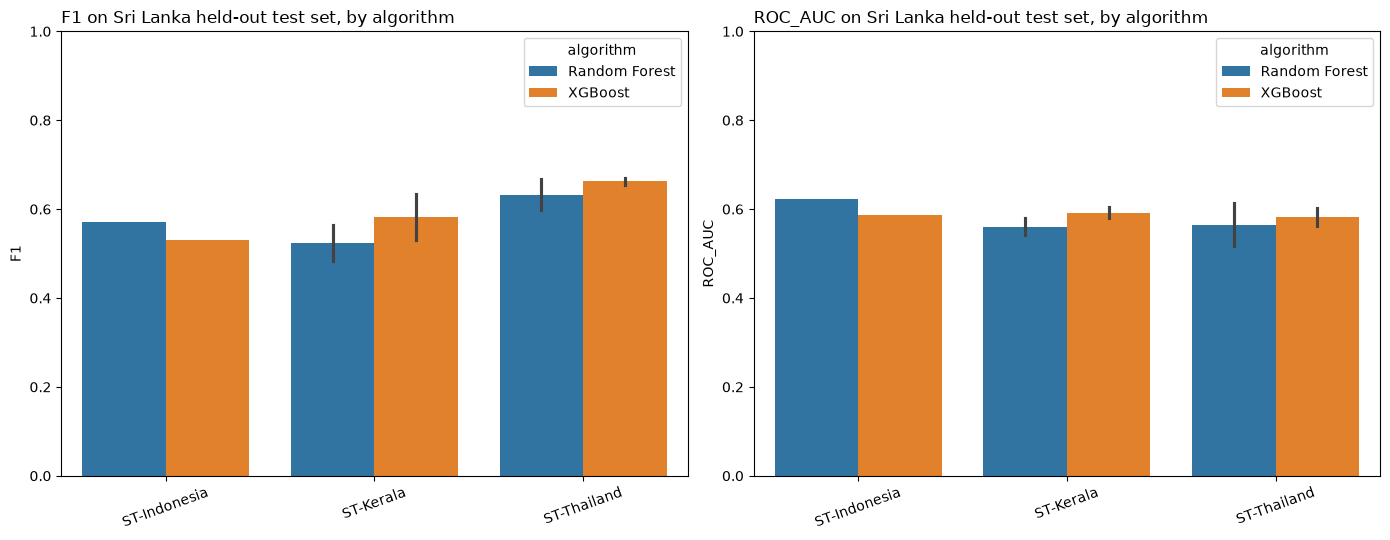

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, metric in zip(axes, ["f1", "roc_auc"]):
    sns.barplot(
        data=transfer_results_df,
        x="scenario", y=metric, hue="algorithm",
        ax=ax, dodge=True,
    )
    ax.set_title(metric.upper() + " on Sri Lanka held-out test set, by algorithm", loc="left")
    ax.set_xlabel("")
    ax.set_ylabel(metric.upper())
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, 1)

plt.tight_layout()
fig.savefig(FIGURE_DIR / "transfer_algorithm_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Save results for Chapter 5

In [17]:
results_out = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "comparison_table": comparison_df.to_dict(orient="records"),
    "full_transfer_results": transfer_results_df.to_dict(orient="records"),
}

out_path = MODEL_DIR / "cross_domain_transfer_results.json"
out_path.write_text(json.dumps(results_out, indent=2, default=str), encoding="utf-8")

comparison_df.to_csv(MODEL_DIR / "cross_domain_transfer_comparison.csv", index=False)

print("Saved:", out_path)
print("Saved:", MODEL_DIR / "cross_domain_transfer_comparison.csv")


Saved: D:\PROJECTS\Landslide_prediction\data\processed\models\cross_domain_transfer_results.json
Saved: D:\PROJECTS\Landslide_prediction\data\processed\models\cross_domain_transfer_comparison.csv
